In [60]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict

In [61]:
def generate_random_weighted_graph(n, low, high):
    g = nx.generators.complete_graph(n)
    g.add_weighted_edges_from([(a, b, np.random.randint(1,20)) for a, b in g.edges()])
    nx.set_node_attributes(g, nx.spring_layout(g), "pos")
    return g

In [62]:

def plot_graph(g, title="", highlight_edges=[]):
    pos = nx.get_node_attributes(g, "pos")
    plt.title(title)
    nx.draw(g, pos=pos, labels={x: x for x in g.nodes})
    weights = nx.get_edge_attributes(g, "weight")
    nx.draw_networkx_edge_labels(g, pos, edge_labels=weights)
    nx.draw_networkx_edges(g, pos, edgelist=highlight_edges, edge_color="r")
    nx.draw_networkx_edge_labels(
        g, pos,
        edge_labels={
            e: w
            for e, w in weights.items()
            if e in map(lambda x: tuple(sorted(x)), highlight_edges)
        },
        font_color="r",
    )

np.random.seed(3)
g = generate_random_weighted_graph(7, 1, 20)

In [76]:

def nearest_neighbour_initialization(g, closed_tour=False):
    curr_node = np.random.choice(g.nodes)
    path = [curr_node]
    not_visited = set(g.nodes) - {curr_node}
    while not_visited:
        not_visited_neighbours = not_visited & set(g.neighbors(curr_node))
        curr_node = min(not_visited_neighbours, key=lambda x: g[curr_node][x]["weight"])
        path.append(curr_node)
        not_visited.remove(curr_node)
    if closed_tour:
        path.append(path[0])
    return path

np.random.seed(1)
print(nearest_neighbour_initialization(g))
print(nearest_neighbour_initialization(g, closed_tour=True))

[np.int64(5), 1, 4, 0, 2, 6, 3]
[np.int64(3), 5, 1, 4, 0, 2, 6, np.int64(3)]


In [64]:

def has_cycle(g):
    try:
        nx.find_cycle(g)
    except nx.NetworkXNoCycle:
        return False
    return True

def get_path_from_edges(edges, closed_tour=False):
    path_graph = nx.Graph(edges)
    curr = min(path_graph.nodes, key=path_graph.degree)
    path, visited = [curr], {curr}
    while len(path) < len(path_graph):
        curr = (set(path_graph.neighbors(curr)) - visited).pop()
        visited.add(curr)
        path.append(curr)
    if closed_tour:
        path.append(path[0])
    return path


In [65]:

def shortest_edge_initialization(g, closed_tour=False):
    edge_list = set(g.edges)
    times_visited = defaultdict(int)
    tour = set()
    max_tour_len = len(g) if closed_tour else len(g) - 1
    key = nx.get_edge_attributes(g, "weight").get
    while len(tour) < max_tour_len:
        u, v = min(edge_list, key=key)
        times_visited[u] += 1
        times_visited[v] += 1
        tour.add((u, v))
        edge_list.remove((u, v))
        for u, v in set(edge_list):
            if (
                (has_cycle(nx.Graph(tour | {(u, v)})) and len(tour) != len(g) - 1)
                or times_visited[u] == 2 or times_visited[v] == 2
            ):
                edge_list.remove((u, v))
    return get_path_from_edges(tour, closed_tour=closed_tour)

np.random.seed(1)
print(shortest_edge_initialization(g))
print(shortest_edge_initialization(g, closed_tour=True))


[3, 4, 0, 2, 6, 5, 1]
[0, 2, 6, 5, 1, 3, 4, 0]


In [75]:
def make_valid_tour(p, nodes):
    unvisited=set(nodes)-set(p)
    index=defaultdict(list) 
    for i in range(len(p)):
        visited={node for node in index if len(index[node])==2}
    for node in visited:
        change_index=np.random.choice(index[node])
        p[change_index]=unvisited.pop()
    return p

def partially_matched_crossover(p1, p2):
    pt = np.random.randint(1, len(p1) - 1)
    child1 = p1[:pt] + p2[pt:]
    child2 = p2[:pt] + p1[pt:]

    nodes = set(p1)
    return make_valid_tour(child1, nodes), make_valid_tour(child2, nodes)

def path_length(path):
    distance=0
    for i in range(len(path)-1):
        distance+=g[path[i]][path[i+1]]["weight"]
    return distance

def inv_path_length(path):
    return [1 / path_length(i) for i in path]

def roulette_wheel_selection(fitness,population):
    probabilities = np.array(fitness) / np.sum(fitness)
    return np.random.choice(len(population),size=len(population),p=probabilities)

np.random.seed(3)
population = [nearest_neighbour_initialization(g, closed_tour=False) for i in range(10)]
fitness = inv_path_length(population)
selected_indices = roulette_wheel_selection(fitness, population)
selected_population = [population[i] for i in selected_indices]
parents = selected_population[:2]
print(np.array((parents)).tolist())
#print(partially_matched_crossover(*parents))
print(np.array(partially_matched_crossover(*parents)).tolist())


[[3, 5, 1, 4, 0, 2, 6], [0, 4, 3, 5, 1, 2, 6]]
[[3, 5, 1, 5, 1, 2, 6], [0, 4, 3, 4, 0, 2, 6]]


In [ ]:
def order_crossover(p1, p2):
    start = np.random.randint(0,9)
    end = np.random.randint(start + 1,10)

    def fill_blanks(parent1, parent2, s, e):
        segment = parent1[s:e]
        unvisited_nodes = [node for node in parent2 if node not in segment]
        child = [None] * len(parent1)
        child[s:e] = segment
        j = 0
        for i in range(len(parent1)):
            if i < s or i >= e:
                child[i] = unvisited_nodes[j]
                j += 1
        return child

    c1 = fill_blanks(p1, p2, start, end)
    c2 = fill_blanks(p2, p1, start, end)
    return c1, c2

def path_length(path):
    distance=0
    for i in range(len(path)-1):
        distance+=g[path[i]][path[i+1]]["weight"]
    return distance

def inv_path_length(path):
    return [1 / path_length(i) for i in path]

def roulette_wheel_selection(fitness,population):
    probabilities = np.array(fitness) / np.sum(fitness)
    return np.random.choice(len(population),size=len(population),p=probabilities)

np.random.seed(3)

population = [nearest_neighbour_initialization(g, closed_tour=False) for i in range(10)]
fitness = inv_path_length(population)
selected_indices = roulette_wheel_selection(fitness, population)
selected_population = [population[i] for i in selected_indices]
parents = selected_population[:2]
print(population[:2])
print(order_crossover(*parents))

[[np.int64(2), 6, 5, 1, 4, 0, 3], [np.int64(0), 4, 3, 5, 1, 2, 6]]
([3, 5, 1, 4, 0, 2, 6], [4, 0, 3, 5, 1, 2, 6])


In [ ]:
def inversion_mutation(p):
    start = np.random.randint(0,len(p)-1)
    end = np.random.randint(start+1,len(p)+1)
    c = p.copy()
    sub=p[start:end]
    for i in range(start,end):
        c[i]=sub.pop()
    return c


np.random.seed(3)
population = [nearest_neighbour_initialization(g, closed_tour=False) for i in range(10)]
subject = population[0]
print(subject, inversion_mutation(subject))


[np.int64(2), 6, 5, 1, 4, 0, 3] [np.int64(2), 6, 0, 4, 1, 5, 3]


In [ ]:
def insertion_mutation(p):
    i = np.random.randint(1, len(p))
    k = np.random.randint(0, len(p)-1)
    c = p.copy()
    c.insert(k,c.pop(i))
    return c


np.random.seed(3)
population = [nearest_neighbour_initialization(g, closed_tour=False) for i in range(10)]
subject = population[0]
print(subject, insertion_mutation(subject))


[np.int64(2), 6, 5, 1, 4, 0, 3] [np.int64(2), 6, 5, 1, 4, 0, 3]


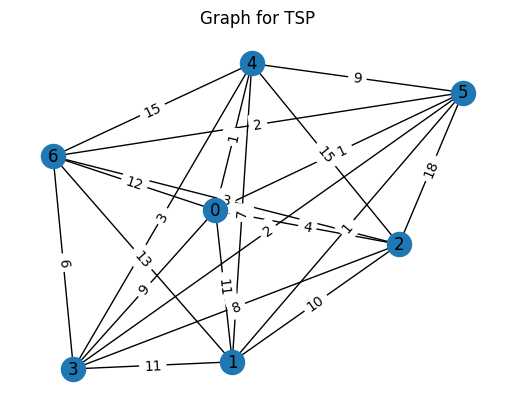

In [ ]:
plot_graph(g, "Graph for TSP")